# Bandit Auction — Discrete Single Good

Two buyers, one good, discrete types {1, 2, 3}, horizon T=5.
Benchmark: Pavan et al. dynamic optimal ≈ 7.67.

Acceptance-based training with **eval IC** (oracle re-opt restarts) gating checkpoints.
Set `RUN_ENV = 'colab'` or `'local'`.

In [1]:
RUN_ENV = 'colab'   # 'colab' | 'local'
LOCAL_PROJECT_DIR = None
# LOCAL_PROJECT_DIR = r'E:\Research\code\Dynamic Mechanism Design\Bandit Auction'

In [2]:
import os, sys, subprocess

if RUN_ENV == 'colab':
    subprocess.check_call([sys.executable, '-m', 'pip', 'uninstall', '-y',
        'jax', 'jaxlib', 'jax-cuda12-plugin', 'jax-cuda12-pjrt'],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-qU',
        'jax[cuda12]', 'dm-haiku', 'optax', 'flax'])
    print('Install done. IMPORTANT: Runtime → Restart session, then re-run from this cell.')
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/My Research/Dynamic Mechanism Design/Bandit Auction')
        print(f'Working directory: {os.getcwd()}')
    except ImportError:
        print('(Drive mount skipped — restart first.)')
elif RUN_ENV == 'local':
    if LOCAL_PROJECT_DIR:
        os.chdir(LOCAL_PROJECT_DIR)
    print(f'Working directory: {os.getcwd()}')

Install done. IMPORTANT: Runtime → Restart session, then re-run from this cell.
Mounted at /content/drive
Working directory: /content/drive/MyDrive/My Research/Dynamic Mechanism Design/Bandit Auction


In [3]:
import jax
import jax.numpy as jnp
import haiku as hk
import optax
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pickle, json, os

from bandit_auction.core import (
    AuctionSimulator, DiscretePolicy, build_discrete_policy_net,
)
from bandit_auction.mechanisms.network import Mechanism, build_mechanism_network
from bandit_auction.train.binary_search import (
    train_with_checkpoints, evaluate_checkpoint_list, DEFAULT_BS_CFG,
)
from bandit_auction.train.run_penalty import nested_GD_penalty
from bandit_auction.train.evaluate import eval_mechanism_multikey, print_eval_report
from bandit_auction.envs.discrete_single import create_discrete_single_auction

print('JAX devices:', jax.devices())

JAX devices: [CudaDevice(id=0)]


## Configuration

`PROFIT_GOAL` is set directly — no binary search. Adjust based on prior knowledge of the feasible revenue range (Pavan benchmark ≈ 7.67).

In [4]:
EXPERIMENT  = 'discrete_single'
IS_DISCRETE = True
PROFIT_GOAL = 7.5    # Pavan benchmark ~7.67; set slightly below
SEED        = 42

cfg = {**DEFAULT_BS_CFG,
    # Training
    'lr_theta':           1e-4,
    'lr_w':               5e-4,
    'num_outer_epochs':   2000,
    'num_inner_steps':    500,
    'num_samples_train':  128,
    'alpha_base':         5.0,
    'beta_weight':        5.0,
    'pg_base':            PROFIT_GOAL,   # alpha scales as alpha_base * (p / pg_base)
    'print_iter':         50,
    # Checkpoint gating (training IC/IR)
    'checkpoint_thresh':  0.15,
    'checkpoint_interval': 50,
    # Eval IC (re-opt oracle)
    'ic_thresh':          0.05,
    'gap_thresh':         0.1,
    'ic_reopt_steps':     600,
    'ic_reopt_restarts':  3,
    'ic_reopt_lr':        5e-4,
    'ic_reopt_samples':   128,
    # Final eval
    'eval_num_keys':      32,
    'eval_num_samples':   256,
}
print('Config loaded. profit_goal =', PROFIT_GOAL)

Config loaded. profit_goal = 7.5


## Build Environment and Networks

In [5]:
auction = create_discrete_single_auction(
    n_buyers=2, n_goods=1, horizon=5, discount=0.9,
    type_values=[1.0, 2.0, 3.0], allocation_cost=0.1, seed=SEED,
)
print(f'Auction: {auction.num_buyers}B x {auction.num_goods}G x T={auction.num_horizons}')
print(f'Type values: {auction.buyer_types[0, :, 0]}')

s0 = auction.get_initial_state(jax.random.PRNGKey(0))
print(f'Initial types: {s0.current_type}')

Auction: 2B x 1G x T=5
Type values: [1. 2. 3.]
Initial types: [[2.]
 [2.]]


In [6]:
mechanism_network = build_mechanism_network()
policy_network = build_discrete_policy_net(
    d_priv=auction.d_priv, d_pub=auction.d_pub, hidden=128,
)

# Parameter count
_prng = hk.PRNGSequence(SEED)
_mnet = mechanism_network
_b0   = auction.get_initial_belief_state(s0)
_mp   = _mnet.init(next(_prng), s0, jnp.zeros((auction.num_buyers, auction.num_goods)), auction)
_pp   = policy_network.init(next(_prng), _b0, auction)
print(f'Mechanism params: {sum(p.size for p in jax.tree_util.tree_leaves(_mp)):,}')
print(f'Policy params:    {sum(p.size for p in jax.tree_util.tree_leaves(_pp)):,}')

Mechanism params: 46,707
Policy params:    17,286


## Test: Oracle Inner Loop (Maximize Cumulative Regret)

Run the inner optimization loop against a **fixed** mechanism to verify that the oracle converges and finds profitable deviations. This is a sanity check before full training.

- `TEST_MECHANISM_PARAMS = None` uses a **randomly initialized** mechanism.
- Set it to trained params (e.g. `best_mechanism_params` from a prior run) to measure how much regret a trained mechanism actually allows.

The regret curve should climb from near-0 and plateau. If it stays flat at 0 throughout, the oracle is not finding deviations — increase `ORACLE_TEST_STEPS` or check the policy initialization.

Using provided mechanism params.
Restart 1/3
  step    0: regret = -0.002259
  step  100: regret = -0.190959
  step  200: regret = -0.208481
  step  300: regret = -0.285970
  step  400: regret = -0.133376
  → restart best: 0.003536
Restart 2/3
  step    0: regret = -0.050614
  step  100: regret = -0.294506
  step  200: regret = -0.182170
  step  300: regret = -0.253058
  step  400: regret = -0.264750
  → restart best: 0.016636
Restart 3/3
  step    0: regret = -0.033649
  step  100: regret = -0.145510
  step  200: regret = -0.227443
  step  300: regret = -0.217476
  step  400: regret = -0.239919
  → restart best: -0.003832


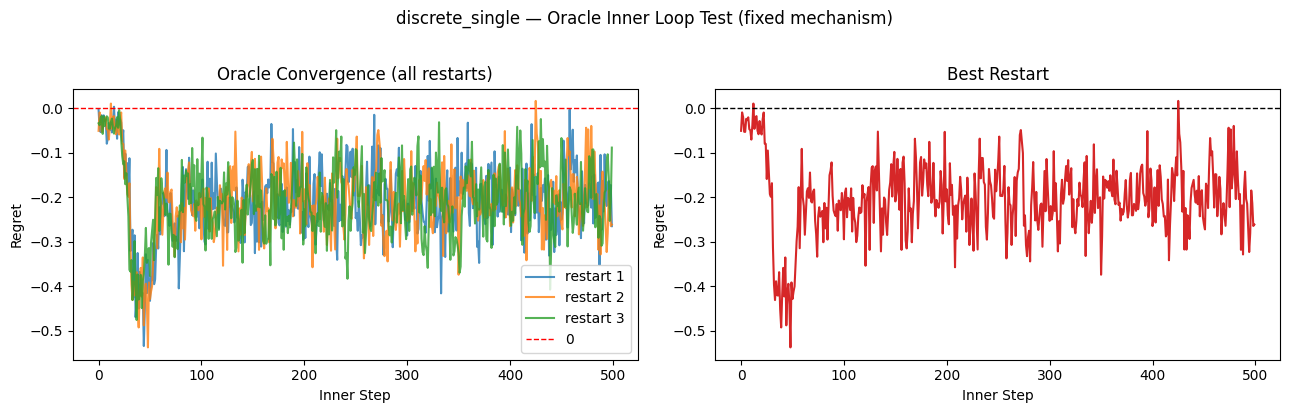


Best regret across all restarts: 0.016636
(If this stays near 0, the oracle cannot find deviations — mechanism may already be approximately IC, or oracle needs more steps/LR.)


In [ ]:
# ---- Oracle test configuration ----
ORACLE_TEST_STEPS    = 500    # inner gradient-ascent steps (matches num_inner_steps)
ORACLE_TEST_RESTARTS = 3      # independent random restarts
ORACLE_TEST_LR       = cfg['lr_w']  # reuse training inner LR
ORACLE_TEST_SAMPLES  = 128     # MC samples per regret estimate
# TEST_MECHANISM_PARAMS = None  # None → random init; or set to best_mechanism_params
TEST_MECHANISM_PARAMS = loaded_penalty_mechanism_params
# Change this seed to test a different random mechanism.
ORACLE_MECHANISM_SEED = 77

# ---- Build oracle networks ----
_oracle_mnet = mechanism_network

# Oracle policy: lower proto_strength so Gumbel-softmax Jacobian is non-trivial at init.
# Default proto=10 saturates softmax → [0.9999, 0.0001, 0.0001] → near-zero gradient →
# oracle cannot escape the truthful initialization via gradient ascent.
# proto=1.0 gives softmax ≈ [0.58, 0.21, 0.21] for 3 types, allowing gradient to flow.
# residual_init_std=0.1 ensures each restart starts from a different random deviation.
_oracle_pnet = build_discrete_policy_net(
    d_priv=auction.d_priv, d_pub=auction.d_pub, hidden=128,
    proto_strength_init=5.0, residual_init_std=0.0,
)

# ---- Initialize test mechanism params ----
_oracle_prng = hk.PRNGSequence(ORACLE_MECHANISM_SEED)
_oracle_s0   = auction.get_initial_state(next(_oracle_prng))
if TEST_MECHANISM_PARAMS is None:
    _test_mparams = _oracle_mnet.init(
        next(_oracle_prng), _oracle_s0,
        jnp.zeros((auction.num_buyers, auction.num_goods)), auction,
    )
    print(f'Using randomly initialized mechanism (ORACLE_MECHANISM_SEED={ORACLE_MECHANISM_SEED}).')
else:
    _test_mparams = TEST_MECHANISM_PARAMS
    print('Using provided mechanism params.')
_test_mechanism = Mechanism(_oracle_mnet, _test_mparams)

# ---- JIT-compiled oracle step ----
_oracle_opt = optax.adam(ORACLE_TEST_LR)

@jax.jit
def _oracle_step(policy_params, w_opt_state, key):
    _reg, _grad = jax.value_and_grad(
        lambda pp: AuctionSimulator.estimate_cumulative_regret(
            auction, _test_mechanism,
            DiscretePolicy(_oracle_pnet, pp),
            ORACLE_TEST_SAMPLES, key,
            auction.get_next_belief_state_discrete,
        )
    )(policy_params)
    _grad_asc = jax.tree_util.tree_map(lambda g: -g, _grad)
    _upd, w_opt_state = _oracle_opt.update(_grad_asc, w_opt_state, policy_params)
    policy_params = optax.apply_updates(policy_params, _upd)
    return _reg, policy_params, w_opt_state

# ---- Run oracle for each restart ----
_oracle_curves   = []
_oracle_best_reg = -float('inf')
_oracle_key_base = ORACLE_MECHANISM_SEED * 1_000_000

for _restart in range(ORACLE_TEST_RESTARTS):
    _b0  = auction.get_initial_belief_state(_oracle_s0)
    _pp  = _oracle_pnet.init(next(_oracle_prng), _b0, auction)
    _ws  = _oracle_opt.init(_pp)
    _curve = []
    print(f'Restart {_restart+1}/{ORACLE_TEST_RESTARTS}')
    for _step in range(ORACLE_TEST_STEPS):
        _key = jax.random.PRNGKey(_oracle_key_base + _restart * 100_000 + _step)
        _reg, _pp, _ws = _oracle_step(_pp, _ws, _key)
        _curve.append(float(_reg))
        if _step % 100 == 0:
            print(f'  step {_step:4d}: regret = {float(_reg):.6f}')
    _oracle_curves.append(_curve)
    _oracle_best_reg = max(_oracle_best_reg, max(_curve))
    print(f'  → restart best: {max(_curve):.6f}')

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for _r, _c in enumerate(_oracle_curves):
    axes[0].plot(_c, alpha=0.8, label=f'restart {_r+1}')
axes[0].axhline(0, color='red', linestyle='--', lw=1, label='0')
axes[0].set_xlabel('Inner Step'); axes[0].set_ylabel('Regret')
axes[0].set_title('Oracle Convergence (all restarts)'); axes[0].legend()
_best_c = _oracle_curves[max(range(len(_oracle_curves)), key=lambda r: max(_oracle_curves[r]))]
axes[1].plot(_best_c, color='tab:red')
axes[1].axhline(0, color='k', linestyle='--', lw=1)
axes[1].set_xlabel('Inner Step'); axes[1].set_ylabel('Regret')
axes[1].set_title('Best Restart')
plt.suptitle(f'{EXPERIMENT} — Oracle Inner Loop Test (fixed mechanism)', y=1.02)
plt.tight_layout(); plt.show()
print(f'\nBest regret across all restarts: {_oracle_best_reg:.6f}')
print('(If this stays near 0, the oracle cannot find deviations — '
      'mechanism may already be approximately IC, or oracle needs more steps/LR.)')

# Acceptance

## Training with Checkpoint Recording

`train_with_checkpoints` runs nested GD and records every checkpoint where training IC ≤ `checkpoint_thresh` and training IR ≤ `checkpoint_thresh`. The final epoch is always included as a candidate.

**Note:** Checkpoints are gated on *training* losses (cheap). The next cell evaluates each checkpoint with the tighter *eval* IC criterion (oracle re-opt restarts).

In [ ]:
checkpoints, logs = train_with_checkpoints(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    profit_goal=PROFIT_GOAL,
    cfg=cfg,
    is_discrete=IS_DISCRETE,
    seed=SEED,
    verbose=True,
)
print(f'\nTraining complete. Candidate checkpoints: {len(checkpoints)}')

  [train] profit_goal=7.500  alpha=5.00  lr_theta=1.0e-04  lr_w=5.0e-04
=== Outer Epoch 0 (49.0s) ===
  oracle regret:  0.601472
  reg:            0.598897   reg_+=0.598897
  gap:            7.064610   gap_+=7.064610
  ir_loss:        0.000000
  total loss:     10.059096
=== Outer Epoch 50 (113.4s) ===
  oracle regret:  -0.009894
  reg:            -0.013375   reg_+=0.000000
  gap:            6.107017   gap_+=6.107017
  ir_loss:        0.000000
  total loss:     6.107017
=== Outer Epoch 100 (176.6s) ===
  oracle regret:  0.025352
  reg:            0.031503   reg_+=0.031503
  gap:            3.061008   gap_+=3.061008
  ir_loss:        0.021311
  total loss:     3.325077
=== Outer Epoch 150 (240.0s) ===
  oracle regret:  -0.002557
  reg:            0.000196   reg_+=0.000196
  gap:            1.436670   gap_+=1.436670
  ir_loss:        0.113812
  total loss:     2.006707
=== Outer Epoch 200 (303.5s) ===
  oracle regret:  -0.027748
  reg:            -0.020942   reg_+=0.000000
  gap:        

## Checkpoint Evaluation — Eval IC + IR with Oracle Re-opt

For each candidate checkpoint, the oracle is re-optimized from scratch (`ic_reopt_restarts` × `ic_reopt_steps` gradient ascent steps). A checkpoint **PASS**es if:
- `max(IC_reopt, IC_eval) ≤ ic_thresh` (= 0.05)
- `profit_goal − revenue_eval ≤ gap_thresh` (= 0.1)
- `IR_eval ≤ ir_thresh` (= 0.05)

Checkpoints are sorted: feasible first, then by descending revenue.

In [ ]:
eval_results = evaluate_checkpoint_list(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    checkpoints=checkpoints,
    profit_goal=PROFIT_GOAL,
    cfg=cfg,
    is_discrete=IS_DISCRETE,
    seed=SEED,
    verbose=True,
)

feasible = [r for r in eval_results if r['feasible']]
print(f'\n{len(feasible)} / {len(eval_results)} checkpoints PASS eval (IC + IR + gap).')
if feasible:
    best = feasible[0]
    best_mechanism_params = best['mechanism_params']
    best_policy_params    = best.get('reopt_policy_params', best['policy_params'])
    print(f'Best: epoch={best["epoch"]}  rev={best["revenue_eval"]:.4f}  '
          f'IC_reopt={best["regret_reopt"]:.4f}  IC_eval={best["regret_eval"]:.4f}  '
          f'IR_eval={best["ir_loss_eval"]:.4f}')
else:
    print('No feasible checkpoint. Using checkpoint with lowest eval IC.')
    best = min(eval_results, key=lambda r: r['regret_eval'])
    best_mechanism_params = best['mechanism_params']
    best_policy_params    = best.get('reopt_policy_params', best['policy_params'])
    print(f'Lowest IC: epoch={best["epoch"]}  IC_eval={best["regret_eval"]:.4f}  '
          f'IR_eval={best["ir_loss_eval"]:.4f}')

## Checkpoint Summary Table

In [ ]:
print(f'\n{"="*80}')
print(f'  {EXPERIMENT} — Checkpoint Evaluation Summary  (profit_goal={PROFIT_GOAL})')
print(f'{"="*80}')
print(f'  {"Epoch":>6} | {"Rev":>7} | {"Gap":>6} | {"IC_reopt":>8} | {"IC_eval":>8} | {"IR_eval":>7} | Result')
print('  ' + '-'*70)
for r in sorted(eval_results, key=lambda x: x['epoch']):
    _flag = 'PASS ★' if r['feasible'] else 'fail  '
    print(f'  {r["epoch"]:>6} | {r["revenue_eval"]:>7.4f} | '
          f'{PROFIT_GOAL - r["revenue_eval"]:>6.4f} | '
          f'{r["regret_reopt"]:>8.4f} | '
          f'{r["regret_eval"]:>8.4f} | '
          f'{r["ir_loss_eval"]:>7.4f} | {_flag}')


  discrete_single — Checkpoint Evaluation Summary  (profit_goal=7.5)
   Epoch |     Rev |    Gap | IC_reopt |  IC_eval | IR_eval | Result
  ----------------------------------------------------------------------
      50 |  1.4536 | 6.0464 |   0.0117 |  -0.0000 |  0.0000 | fail  
     100 |  4.5242 | 2.9758 |  -0.0602 |  -0.0809 |  0.0213 | fail  
     150 |  6.0086 | 1.4914 |  -0.0186 |  -0.0221 |  0.1232 | fail  
     400 |  7.2078 | 0.2922 |  -0.4135 |  -0.4310 |  0.1242 | fail  
     550 |  7.1314 | 0.3686 |  -0.4480 |  -0.5194 |  0.0810 | fail  
     600 |  7.4524 | 0.0476 |  -0.3305 |  -0.3855 |  0.1075 | fail  
     650 |  7.3410 | 0.1590 |  -0.4808 |  -0.5135 |  0.0877 | fail  
     700 |  7.3410 | 0.1590 |  -0.3498 |  -0.3784 |  0.0735 | fail  
     750 |  7.6556 | -0.1556 |  -0.4298 |  -0.4745 |  0.1118 | fail  
     800 |  7.3674 | 0.1326 |  -0.3857 |  -0.5191 |  0.0701 | fail  
     850 |  6.8726 | 0.6274 |  -0.5648 |  -0.6718 |  0.0288 | fail  
     900 |  7.4080 | 0.0920 

## Convergence Curves with Checkpoint Markers

- **Green ★** = PASS (eval IC ≤ 0.05, IR ≤ 0.05, revenue gap ≤ 0.1)
- **Red ✗** = fail
- Dashed green vertical = selected best checkpoint

In [ ]:
# Build epoch-indexed arrays for checkpoint markers
_ckpt_by_epoch = {r['epoch']: r for r in eval_results}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
_curves = [logs['reg_plus'], logs['gap_plus'], logs['ir']]
_titles = ['IC Regret+', 'Profit Gap+', 'IR Loss']
_cols   = ['tab:blue', 'tab:orange', 'tab:green']

for ax, curve, title, col in zip(axes, _curves, _titles, _cols):
    ax.plot(curve, color=col, alpha=0.85, lw=1.2)
    ax.axhline(0, color='k', lw=0.6, linestyle='--', alpha=0.4)
    ax.set_xlabel('Epoch'); ax.set_title(title)

axes[0].axhline(cfg['ic_thresh'], color='red', lw=0.8, linestyle=':', label=f'IC thresh={cfg["ic_thresh"]}')
axes[0].legend(fontsize=8)

# Checkpoint markers
for epoch, r in sorted(_ckpt_by_epoch.items()):
    _pass = r['feasible']
    _col  = 'limegreen' if _pass else 'crimson'
    _mk   = '*' if _pass else 'X'
    _ms   = 180 if _pass else 80
    for i, (ax, curve) in enumerate(zip(axes, _curves)):
        _y = curve[min(epoch, len(curve) - 1)]
        ax.scatter([epoch], [_y], color=_col, marker=_mk, s=_ms, zorder=6,
                   edgecolors='black' if _pass else _col, linewidths=0.5)

# Legend for markers
_legend_elems = [
    Line2D([0],[0], marker='*', color='w', markerfacecolor='limegreen',
           markeredgecolor='black', markersize=11, label='PASS (eval IC ≤ thresh, IR ≤ thresh)'),
    Line2D([0],[0], marker='X', color='w', markerfacecolor='crimson',
           markersize=9, label='fail'),
]
axes[2].legend(handles=_legend_elems, loc='upper right', fontsize=8)

if feasible:
    for ax in axes:
        ax.axvline(best['epoch'], color='limegreen', lw=1.5, linestyle='--', alpha=0.6)

plt.suptitle(f'{EXPERIMENT} — Training Curves (profit_goal={PROFIT_GOAL})', y=1.02)
plt.tight_layout(); plt.show()

print(f'Oracle regret (last inner step): {logs["oracle_reg_last"][-1]:.4f}')

## Final Evaluation on Best Checkpoint

In [ ]:
final_eval_keys = jax.random.split(jax.random.PRNGKey(88888), cfg['eval_num_keys'])
final_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=best_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=final_eval_keys,
    policy_network=policy_network,
    policy_params=best_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(final_results, prefix=f'{EXPERIMENT} best checkpoint (epoch {best["epoch"]}): ')


  discrete_single best checkpoint (epoch 1999): Evaluation Report
  profit                   : 7.6059 ± 0.0596  [7.4726, 7.7514]
  gap plus                 : 0.0011 ± 0.0049  [0.0000, 0.0274]
  buyer surplus            : 1.8364 ± 0.0409  [1.7453, 1.9137]
  ir loss                  : 0.0433 ± 0.0062  [0.0309, 0.0584]
  ic regret                : -0.0258 ± 0.0375



## Save Outputs

In [ ]:
save_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}'
os.makedirs(save_dir, exist_ok=True)

with open(f'{save_dir}/mechanism_params.pkl', 'wb') as f:
    pickle.dump(best_mechanism_params, f)
with open(f'{save_dir}/policy_params.pkl', 'wb') as f:
    pickle.dump(best_policy_params, f)

_summary = {
    'experiment':   EXPERIMENT,
    'profit_goal':  PROFIT_GOAL,
    'best_epoch':   int(best['epoch']),
    'revenue_eval': float(best['revenue_eval']),
    'regret_reopt': float(best['regret_reopt']),
    'regret_eval':  float(best['regret_eval']),
    'ir_loss_eval': float(best['ir_loss_eval']),
    'feasible':     bool(best['feasible']),
    'num_pass':     len(feasible),
    'num_candidates': len(eval_results),
    'cfg':          {k: v for k, v in cfg.items() if not callable(v)},
    'final_eval':   {k: v for k, v in final_results.items() if isinstance(v, dict)},
}
with open(f'{save_dir}/summary.json', 'w') as f:
    json.dump(_summary, f, indent=2)

_curves_out = {
    'reg_plus': [float(x) for x in logs['reg_plus']],
    'gap_plus': [float(x) for x in logs['gap_plus']],
    'ir':       [float(x) for x in logs['ir']],
    'reg':      [float(x) for x in logs['reg']],
    'checkpoints_eval': [
        {'epoch': r['epoch'], 'revenue_eval': r['revenue_eval'],
         'regret_reopt': r['regret_reopt'], 'regret_eval': r['regret_eval'],
         'ir_loss_eval': r['ir_loss_eval'], 'feasible': r['feasible']}
        for r in sorted(eval_results, key=lambda x: x['epoch'])
    ],
}
with open(f'{save_dir}/training_curves.json', 'w') as f:
    json.dump(_curves_out, f, indent=2)

print(f'Saved to: {save_dir}/')
print(f'  mechanism_params.pkl, policy_params.pkl, summary.json, training_curves.json')

Saved to: outputs/discrete_single/acceptance/seed42/
  mechanism_params.pkl, policy_params.pkl, summary.json, training_curves.json


# Penalty

In [ ]:
# ---- Penalty training configuration ----
# Set alpha and beta independently from the acceptance method — tune as needed.
PENALTY_ALPHA = 20.0   # IC penalty weight
PENALTY_BETA  = 20.0   # IR penalty weight
print(f'Penalty: alpha={PENALTY_ALPHA}, beta={PENALTY_BETA}')

# ---- Train ----
logs_penalty = nested_GD_penalty(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    num_outer_epochs=cfg['num_outer_epochs'],
    lr_theta=cfg['lr_theta'],
    num_inner_steps=cfg['num_inner_steps'],
    lr_w=cfg['lr_w'],
    num_samples_train=cfg['num_samples_train'],
    alpha_weight=PENALTY_ALPHA,
    beta_weight=PENALTY_BETA,
    print_iter=cfg['print_iter'],
    checkpoint_thresh=cfg['checkpoint_thresh'],
    checkpoint_interval=cfg['checkpoint_interval'],
    is_discrete=IS_DISCRETE,
    seed=SEED,
)


Penalty: alpha=20.0, beta=20.0
=== Outer Epoch 0 (25.7s) ===
  oracle regret (train):  0.601235
  reg (in loss):          0.598661   reg_+=0.598661
  profit:                 0.434983
  ir_loss:                0.000000
  total loss:             11.538247
=== Outer Epoch 50 (107.6s) ===
  oracle regret (train):  0.000372
  reg (in loss):          -0.001404   reg_+=0.000000
  profit:                 0.332721
  ir_loss:                0.000000
  total loss:             -0.332721
=== Outer Epoch 100 (189.0s) ===
  oracle regret (train):  0.000000
  reg (in loss):          0.000000   reg_+=0.000000
  profit:                 1.117658
  ir_loss:                0.000000
  total loss:             -1.117658
=== Outer Epoch 150 (270.6s) ===
  oracle regret (train):  0.006831
  reg (in loss):          0.006666   reg_+=0.006666
  profit:                 2.105764
  ir_loss:                0.000000
  total loss:             -1.972434
=== Outer Epoch 200 (352.2s) ===
  oracle regret (train):  -0.001469

In [ ]:
# Append final-epoch checkpoint
checkpoints_penalty = logs_penalty['checkpoint_mech'] + [{
    'epoch':            cfg['num_outer_epochs'] - 1,
    'reg_train':        logs_penalty['reg'][-1],
    'ir_train':         logs_penalty['ir'][-1],
    'profit_train':     logs_penalty['profit'][-1],
    'mechanism_params': logs_penalty['mechanism_params'],
    'policy_params':    logs_penalty['policy_params'],
}]

print(f'\nPenalty training complete. Candidate checkpoints: {len(checkpoints_penalty)}')
_penalty_state_dir = f'outputs/{EXPERIMENT}/penalty/seed{SEED}/training_state'
os.makedirs(_penalty_state_dir, exist_ok=True)
with open(f'{_penalty_state_dir}/checkpoints_penalty.pkl', 'wb') as f:
    pickle.dump(checkpoints_penalty, f)
with open(f'{_penalty_state_dir}/logs_penalty.pkl', 'wb') as f:
    pickle.dump(logs_penalty, f)
print(f'Saved {len(checkpoints_penalty)} penalty checkpoints to {_penalty_state_dir}/')



Penalty training complete. Candidate checkpoints: 40
Saved 40 penalty checkpoints to outputs/discrete_single/penalty/seed42/training_state/


## Load and Eval

In [7]:
PENALTY_ALPHA = 20.0   # IC penalty weight
PENALTY_BETA  = 20.0   # IR penalty weight

In [8]:
_penalty_state_dir = f'outputs/{EXPERIMENT}/penalty/seed{SEED}/training_state'
with open(f'{_penalty_state_dir}/checkpoints_penalty.pkl', 'rb') as f:
    checkpoints_penalty = pickle.load(f)
with open(f'{_penalty_state_dir}/logs_penalty.pkl', 'rb') as f:
    logs_penalty = pickle.load(f)
print(f'Loaded {len(checkpoints_penalty)} penalty checkpoints from {_penalty_state_dir}/')


Loaded 40 penalty checkpoints from outputs/discrete_single/penalty/seed42/training_state/


In [9]:
# ---- Checkpoint evaluation ----
# For penalty method: gate on eval IC + eval IR only — no profit-gap constraint.
cfg_penalty = {**cfg, 'gap_thresh': float('inf')}
eval_results_penalty = evaluate_checkpoint_list(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    checkpoints=checkpoints_penalty,
    profit_goal=0.0,
    cfg=cfg_penalty,
    is_discrete=IS_DISCRETE,
    seed=SEED + 1,
    verbose=True,
)
feasible_penalty = [r for r in eval_results_penalty if r['feasible']]
print(f'\n{len(feasible_penalty)} / {len(eval_results_penalty)} penalty checkpoints PASS eval (IC + IR).')
if feasible_penalty:
    best_penalty = feasible_penalty[0]
    print(f'Best: epoch={best_penalty["epoch"]}  rev={best_penalty["revenue_eval"]:.4f}  '
          f'IC_reopt={best_penalty["regret_reopt"]:.4f}  IC_eval={best_penalty["regret_eval"]:.4f}  '
          f'IR_eval={best_penalty["ir_loss_eval"]:.4f}')
else:
    print('No feasible penalty checkpoint. Using checkpoint with lowest eval IC.')
    best_penalty = min(eval_results_penalty, key=lambda r: r['regret_eval'])
    print(f'Lowest IC: epoch={best_penalty["epoch"]}  IC_eval={best_penalty["regret_eval"]:.4f}  '
          f'IR_eval={best_penalty["ir_loss_eval"]:.4f}')
best_penalty_mechanism_params = best_penalty['mechanism_params']
best_penalty_policy_params    = best_penalty.get('reopt_policy_params', best_penalty['policy_params'])


    [ckpt 1/40] epoch=  50 — re-optimising oracle (3 restarts × 600 steps) ...
    [PASS] epoch=  50  rev=0.3505  gap=-0.3505  IC_reopt=0.0034  IC_eval=-0.0009  IR_eval=0.0000
    [ckpt 2/40] epoch= 100 — re-optimising oracle (3 restarts × 600 steps) ...
    [PASS] epoch= 100  rev=1.1463  gap=-1.1463  IC_reopt=0.0035  IC_eval=-0.0001  IR_eval=0.0000
    [ckpt 3/40] epoch= 150 — re-optimising oracle (3 restarts × 600 steps) ...
    [PASS] epoch= 150  rev=2.1097  gap=-2.1097  IC_reopt=0.0133  IC_eval=0.0043  IR_eval=0.0000
    [ckpt 4/40] epoch= 200 — re-optimising oracle (3 restarts × 600 steps) ...
    [PASS] epoch= 200  rev=3.5903  gap=-3.5903  IC_reopt=0.0029  IC_eval=-0.0010  IR_eval=0.0071
    [ckpt 5/40] epoch= 250 — re-optimising oracle (3 restarts × 600 steps) ...
    [PASS] epoch= 250  rev=4.3798  gap=-4.3798  IC_reopt=0.0041  IC_eval=-0.0153  IR_eval=0.0195
    [ckpt 6/40] epoch= 300 — re-optimising oracle (3 restarts × 600 steps) ...
    [PASS] epoch= 300  rev=4.7079  gap=-4.

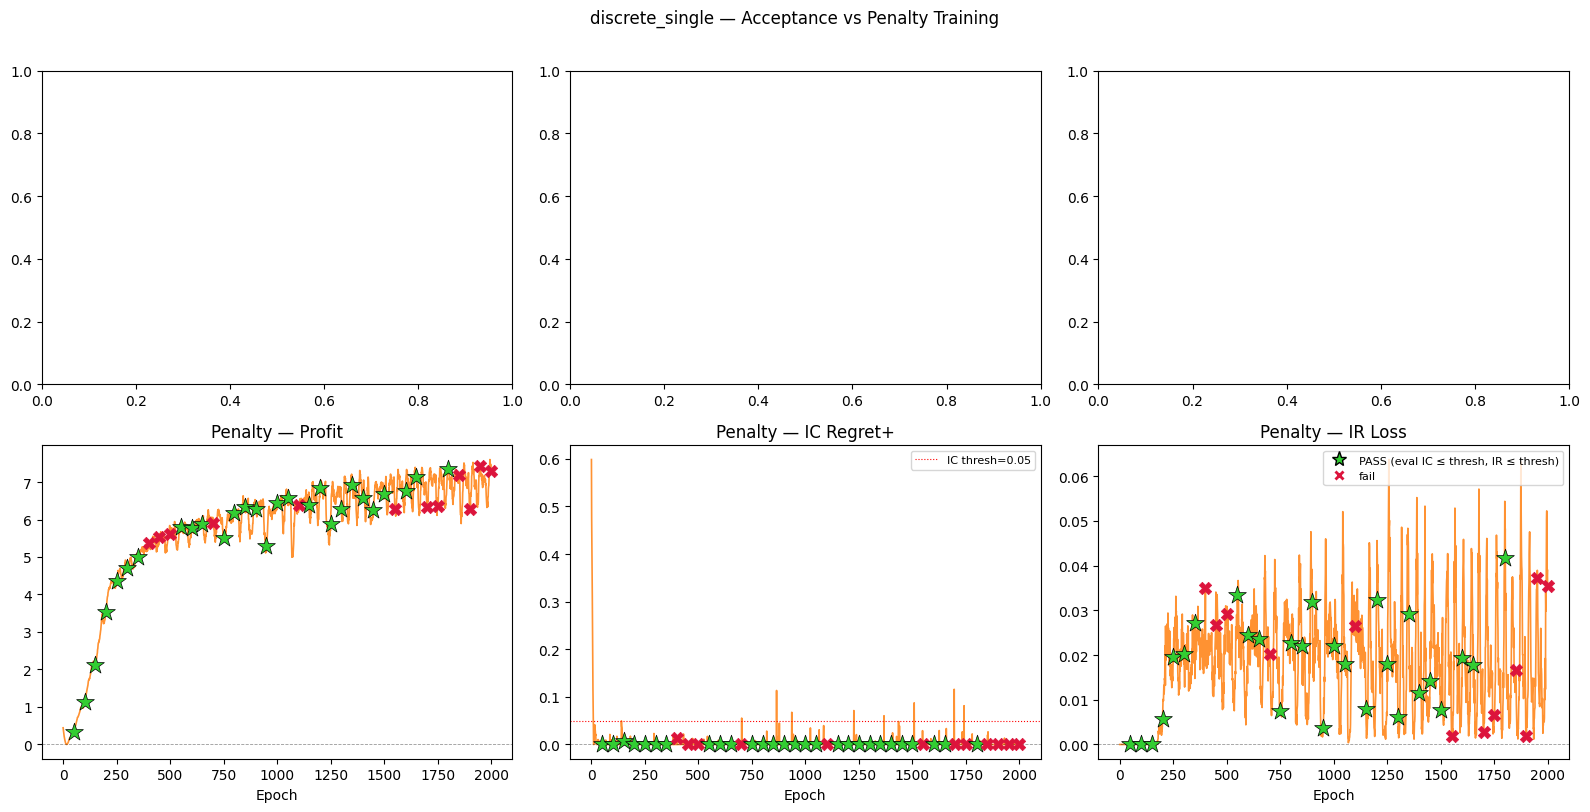

In [10]:
# ---- Convergence curves — Acceptance (top) vs Penalty (bottom) ----
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
_ckpt_by_epoch_penalty = {r['epoch']: r for r in eval_results_penalty}
# _ckpt_by_epoch_accept  = {r['epoch']: r for r in eval_results}

for (row_axes, row_curves, row_titles, row_col, ckpts_dict) in [
    # (axes[0],
    #  [logs['gap_plus'], logs['reg_plus'], logs['ir']],
    #  ['Acceptance — Profit Gap+', 'Acceptance — IC Regret+', 'Acceptance — IR Loss'],
    #  'tab:blue', _ckpt_by_epoch_accept),
    (axes[1],
     [logs_penalty['profit'], logs_penalty['reg_plus'], logs_penalty['ir']],
     ['Penalty — Profit', 'Penalty — IC Regret+', 'Penalty — IR Loss'],
     'tab:orange', _ckpt_by_epoch_penalty),
]:
    for ax, curve, title in zip(row_axes, row_curves, row_titles):
        ax.plot(curve, color=row_col, lw=1.2, alpha=0.85)
        ax.axhline(0, color='k', lw=0.6, linestyle='--', alpha=0.4)
        ax.set_xlabel('Epoch'); ax.set_title(title)
    row_axes[1].axhline(cfg['ic_thresh'], color='red', lw=0.8, linestyle=':', label=f'IC thresh={cfg["ic_thresh"]}')
    row_axes[1].legend(fontsize=8)
    for epoch, r in sorted(ckpts_dict.items()):
        _col = 'limegreen' if r['feasible'] else 'crimson'
        _mk  = '*' if r['feasible'] else 'X'
        _ms  = 180 if r['feasible'] else 80
        for ax, curve in zip(row_axes, row_curves):
            _y = curve[min(epoch, len(curve) - 1)]
            ax.scatter([epoch], [_y], color=_col, marker=_mk, s=_ms, zorder=6,
                       edgecolors='black' if r['feasible'] else _col, linewidths=0.5)

_legend_elems = [
    Line2D([0],[0], marker='*', color='w', markerfacecolor='limegreen',
           markeredgecolor='black', markersize=11, label='PASS (eval IC ≤ thresh, IR ≤ thresh)'),
    Line2D([0],[0], marker='X', color='w', markerfacecolor='crimson', markersize=9, label='fail'),
]
axes[1][2].legend(handles=_legend_elems, loc='upper right', fontsize=8)
plt.suptitle(f'{EXPERIMENT} — Acceptance vs Penalty Training', y=1.01)
plt.tight_layout(); plt.show()


In [11]:
# ---- Final evaluation ----
final_eval_keys_penalty = jax.random.split(jax.random.PRNGKey(99999), cfg['eval_num_keys'])
final_results_penalty = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=best_penalty_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=final_eval_keys_penalty,
    policy_network=policy_network,
    policy_params=best_penalty_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(final_results_penalty, prefix=f'{EXPERIMENT} penalty best (epoch {best_penalty["epoch"]}): ')

# ---- Save ----
save_dir_penalty = f'outputs/{EXPERIMENT}/penalty/seed{SEED}'
os.makedirs(save_dir_penalty, exist_ok=True)
with open(f'{save_dir_penalty}/mechanism_params.pkl', 'wb') as f:
    pickle.dump(best_penalty_mechanism_params, f)
with open(f'{save_dir_penalty}/policy_params.pkl', 'wb') as f:
    pickle.dump(best_penalty_policy_params, f)
_summary_penalty = {
    'experiment': EXPERIMENT, 'method': 'penalty',
    'penalty_alpha': PENALTY_ALPHA, 'penalty_beta': PENALTY_BETA,
    'best_epoch': int(best_penalty['epoch']),
    'revenue_eval': float(best_penalty['revenue_eval']),
    'regret_reopt': float(best_penalty['regret_reopt']),
    'regret_eval':  float(best_penalty['regret_eval']),
    'ir_loss_eval': float(best_penalty['ir_loss_eval']),
    'feasible':     bool(best_penalty['feasible']),
    'num_pass':     len(feasible_penalty),
    'num_candidates': len(eval_results_penalty),
}
with open(f'{save_dir_penalty}/summary.json', 'w') as f:
    json.dump(_summary_penalty, f, indent=2)
_curves_pen_out = {
    'profit':   [float(x) for x in logs_penalty['profit']],
    'reg_plus': [float(x) for x in logs_penalty['reg_plus']],
    'ir':       [float(x) for x in logs_penalty['ir']],
    'reg':      [float(x) for x in logs_penalty['reg']],
    'checkpoints_eval': [
        {'epoch': r['epoch'], 'revenue_eval': r['revenue_eval'],
         'regret_reopt': r['regret_reopt'], 'regret_eval': r['regret_eval'],
         'ir_loss_eval': r['ir_loss_eval'], 'feasible': r['feasible']}
        for r in sorted(eval_results_penalty, key=lambda x: x['epoch'])
    ],
}
with open(f'{save_dir_penalty}/training_curves.json', 'w') as f:
    json.dump(_curves_pen_out, f, indent=2)
print(f'Penalty outputs saved to: {save_dir_penalty}/')


  discrete_single penalty best (epoch 1800): Evaluation Report
  profit                   : 7.3867 ± 0.0611  [7.2740, 7.4985]
  gap plus                 : 0.1133 ± 0.0611  [0.0015, 0.2260]
  buyer surplus            : 1.9488 ± 0.0326  [1.8753, 2.0198]
  ir loss                  : 0.0418 ± 0.0072  [0.0269, 0.0577]
  ic regret                : 0.0001 ± 0.0014

Penalty outputs saved to: outputs/discrete_single/penalty/seed42/


## Reload & Evaluate Saved Results

Load mechanism and policy params from disk and re-evaluate without rerunning training.

**Prerequisite:** Run cells through "Build Environment and Networks" (cells 1–8) so that `auction`, `mechanism_network`, `policy_network`, `cfg`, and `PROFIT_GOAL` are in scope. Training cells are not required.

In [7]:
# ---- Load acceptance results ----
_acc_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}'
with open(f'{_acc_dir}/mechanism_params.pkl', 'rb') as f:
    loaded_mechanism_params = pickle.load(f)
with open(f'{_acc_dir}/policy_params.pkl', 'rb') as f:
    loaded_policy_params = pickle.load(f)
with open(f'{_acc_dir}/summary.json') as f:
    loaded_summary = json.load(f)

print(f'Acceptance — loaded from: {_acc_dir}')
print(f'  epoch={loaded_summary["best_epoch"]}  revenue={loaded_summary["revenue_eval"]:.4f}  '
      f'feasible={loaded_summary["feasible"]}  IC_eval={loaded_summary["regret_eval"]:.4f}  '
      f'IR_eval={loaded_summary["ir_loss_eval"]:.4f}')

_reload_keys = jax.random.split(jax.random.PRNGKey(55555), cfg['eval_num_keys'])
loaded_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=loaded_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=_reload_keys,
    policy_network=policy_network,
    policy_params=loaded_policy_params,
    is_discrete=IS_DISCRETE,
        reopt_steps=600,               # re-optimise oracle from scratch
    reopt_restarts=3,
    reopt_lr=5e-4,
    reopt_samples=128,
)
print_eval_report(loaded_results, prefix=f'{EXPERIMENT} [loaded acceptance]: ')

# ---- Load penalty results ----
_pen_dir = f'outputs/{EXPERIMENT}/penalty/seed{SEED}'
with open(f'{_pen_dir}/mechanism_params.pkl', 'rb') as f:
    loaded_penalty_mechanism_params = pickle.load(f)
with open(f'{_pen_dir}/policy_params.pkl', 'rb') as f:
    loaded_penalty_policy_params = pickle.load(f)
with open(f'{_pen_dir}/summary.json') as f:
    loaded_penalty_summary = json.load(f)

print(f'\nPenalty — loaded from: {_pen_dir}')
print(f'  epoch={loaded_penalty_summary["best_epoch"]}  revenue={loaded_penalty_summary["revenue_eval"]:.4f}  '
      f'feasible={loaded_penalty_summary["feasible"]}  IC_eval={loaded_penalty_summary["regret_eval"]:.4f}  '
      f'IR_eval={loaded_penalty_summary["ir_loss_eval"]:.4f}')

_reload_pen_keys = jax.random.split(jax.random.PRNGKey(66666), cfg['eval_num_keys'])
loaded_penalty_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=loaded_penalty_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=_reload_pen_keys,
    policy_network=policy_network,
    policy_params=loaded_penalty_policy_params,
    is_discrete=IS_DISCRETE,
        reopt_steps=600,               # re-optimise oracle from scratch
    reopt_restarts=3,
    reopt_lr=5e-4,
    reopt_samples=128,
)
print_eval_report(loaded_penalty_results, prefix=f'{EXPERIMENT} [loaded penalty]: ')

Acceptance — loaded from: outputs/discrete_single/acceptance/seed42
  epoch=1999  revenue=7.6061  feasible=True  IC_eval=-0.2834  IR_eval=0.0441

  discrete_single [loaded acceptance]: Evaluation Report
  profit                   : 7.6171 ± 0.0628  [7.4824, 7.7201]
  gap plus                 : 0.0010 ± 0.0038  [0.0000, 0.0176]
  buyer surplus            : 1.8338 ± 0.0363  [1.7759, 1.9060]
  ir loss                  : 0.0446 ± 0.0070  [0.0286, 0.0555]
  ic regret                : 0.0041 ± 0.0072  (reopt peak: 0.0959)


Penalty — loaded from: outputs/discrete_single/penalty/seed42
  epoch=1800  revenue=7.3594  feasible=True  IC_eval=-0.0003  IR_eval=0.0416

  discrete_single [loaded penalty]: Evaluation Report
  profit                   : 7.3767 ± 0.0661  [7.2579, 7.5378]
  gap plus                 : 0.1244 ± 0.0635  [0.0000, 0.2421]
  buyer surplus            : 1.9478 ± 0.0393  [1.8624, 2.0270]
  ir loss                  : 0.0420 ± 0.0065  [0.0274, 0.0556]
  ic regret                : 0